In [1]:
!pip install qiskit qiskit-aer matplotlib numpy pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 27.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.7 MB/s eta 0:00:00


Step 0 -> probability of marked node: 0.25
Step 1 -> probability of marked node: 1.0
Step 2 -> probability of marked node: 0.25
Step 3 -> probability of marked node: 0.25
Step 4 -> probability of marked node: 1.0
Step 5 -> probability of marked node: 0.25
Step 6 -> probability of marked node: 0.25
Step 7 -> probability of marked node: 1.0


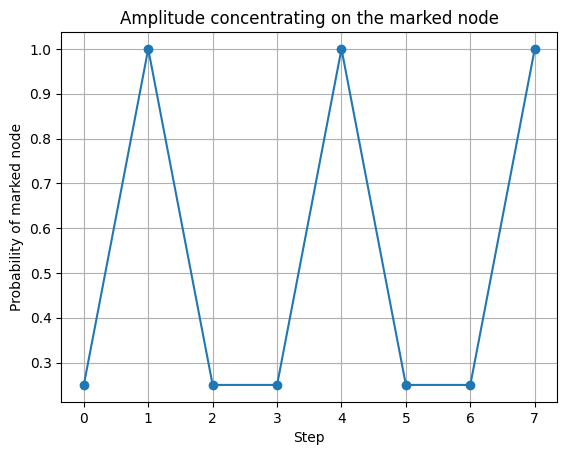

In [2]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

n = 2                      # 2 qubits = 4 nodes. Change to 3 for 8 nodes.
marked = 2**n - 1          # the marked node is |11...1>

def flip_marked(qc):
    # flips the sign of |11...1>
    if n == 2:
        qc.cz(0, 1)
    elif n == 3:
        qc.h(2); qc.ccx(0, 1, 2); qc.h(2)

def oracle(qc):
    flip_marked(qc)

def spread(qc):
    # diffusion: spreads amplitude towards the marked node
    qc.h(range(n)); qc.x(range(n))
    flip_marked(qc)
    qc.x(range(n)); qc.h(range(n))

qc = QuantumCircuit(n)
qc.h(range(n))             # equal start

probs = [Statevector.from_instruction(qc).probabilities()[marked]]

for step in range(1, 8):
    oracle(qc)
    spread(qc)
    probs.append(Statevector.from_instruction(qc).probabilities()[marked])

for s, p in enumerate(probs):
    print("Step", s, "-> probability of marked node:", round(p, 3))

plt.plot(range(len(probs)), probs, marker="o")
plt.xlabel("Step")
plt.ylabel("Probability of marked node")
plt.title("Amplitude concentrating on the marked node")
plt.grid(True)
plt.show()

Quantum: best probability 0.427 at step 3
Classical average hitting time: 2.5 | theory (N^2-1)/6 = 2.5


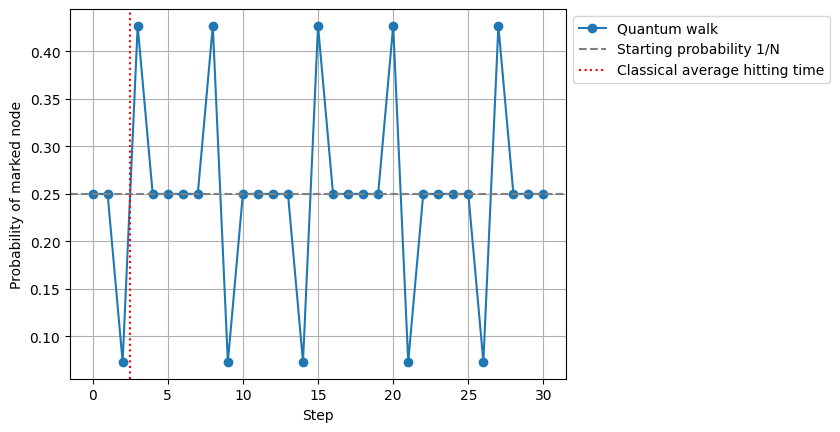

In [4]:
import numpy as np
import matplotlib.pyplot as plt

N = 4            # nodes in the ring (also try 8)
marked = 0
steps = 30

# state = (coin, node). Coin 0 = move right, coin 1 = move left
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

shift = np.zeros((2*N, 2*N))
coin = np.zeros((2*N, 2*N))
for x in range(N):
    shift[(x+1) % N, x] = 1            # right-movers go to the next node
    shift[N + (x-1) % N, N + x] = 1    # left-movers go to the previous node
    c = H if x != marked else -np.eye(2)   # the oracle: a different coin at the marked node
    for a in range(2):
        for b in range(2):
            coin[a*N + x, b*N + x] = c[a, b]

U = shift @ coin                       # one step = coin, then move

psi = np.ones(2*N) / np.sqrt(2*N)      # equal start
q_probs = []
for t in range(steps + 1):
    q_probs.append(abs(psi[marked])**2 + abs(psi[N + marked])**2)
    psi = U @ psi

# Classical random walk: average steps to hit the marked node
rng = np.random.default_rng(1)
def hitting_time(start):
    pos, t = start, 0
    while pos != marked:
        pos = (pos + rng.choice([-1, 1])) % N
        t += 1
    return t

avg = np.mean([hitting_time(rng.integers(N)) for _ in range(20000)])
theory = (N**2 - 1) / 6

print("Quantum: best probability", round(max(q_probs), 3), "at step", int(np.argmax(q_probs)))
print("Classical average hitting time:", round(avg, 2), "| theory (N^2-1)/6 =", round(theory, 2))

plt.plot(q_probs, marker="o", label="Quantum walk")
plt.axhline(1/N, color="gray", linestyle="--", label="Starting probability 1/N")
plt.axvline(avg, color="red", linestyle=":", label="Classical average hitting time")
plt.xlabel("Step")
plt.ylabel("Probability of marked node")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.grid(True)
plt.show()

Quantum: best probability 0.41 at step 29
Classical average hitting time: 10.46 | theory (N^2-1)/6 = 10.5


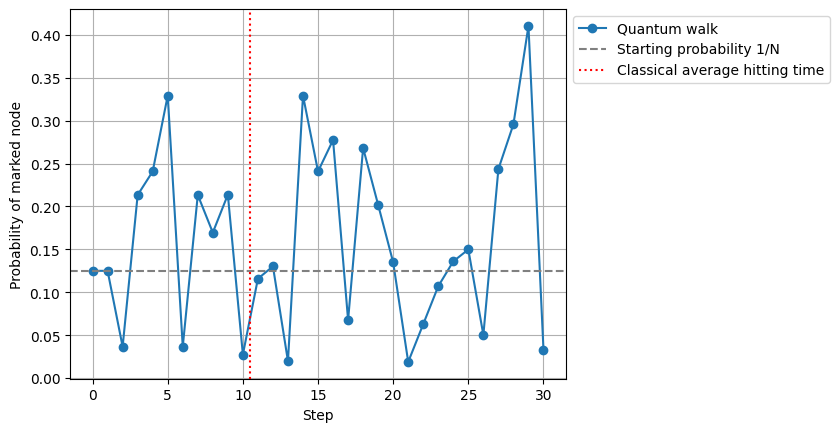

In [5]:
import numpy as np
import matplotlib.pyplot as plt

N = 8
marked = 0
steps = 30

# state = (coin, node). Coin 0 = move right, coin 1 = move left
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

shift = np.zeros((2*N, 2*N))
coin = np.zeros((2*N, 2*N))
for x in range(N):
    shift[(x+1) % N, x] = 1            # right-movers go to the next node
    shift[N + (x-1) % N, N + x] = 1    # left-movers go to the previous node
    c = H if x != marked else -np.eye(2)   # the oracle: a different coin at the marked node
    for a in range(2):
        for b in range(2):
            coin[a*N + x, b*N + x] = c[a, b]

U = shift @ coin                       # one step = coin, then move

psi = np.ones(2*N) / np.sqrt(2*N)      # equal start
q_probs = []
for t in range(steps + 1):
    q_probs.append(abs(psi[marked])**2 + abs(psi[N + marked])**2)
    psi = U @ psi

# Classical random walk: average steps to hit the marked node
rng = np.random.default_rng(1)
def hitting_time(start):
    pos, t = start, 0
    while pos != marked:
        pos = (pos + rng.choice([-1, 1])) % N
        t += 1
    return t

avg = np.mean([hitting_time(rng.integers(N)) for _ in range(20000)])
theory = (N**2 - 1) / 6

print("Quantum: best probability", round(max(q_probs), 3), "at step", int(np.argmax(q_probs)))
print("Classical average hitting time:", round(avg, 2), "| theory (N^2-1)/6 =", round(theory, 2))

plt.plot(q_probs, marker="o", label="Quantum walk")
plt.axhline(1/N, color="gray", linestyle="--", label="Starting probability 1/N")
plt.axvline(avg, color="red", linestyle=":", label="Classical average hitting time")
plt.xlabel("Step")
plt.ylabel("Probability of marked node")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.grid(True)
plt.show()

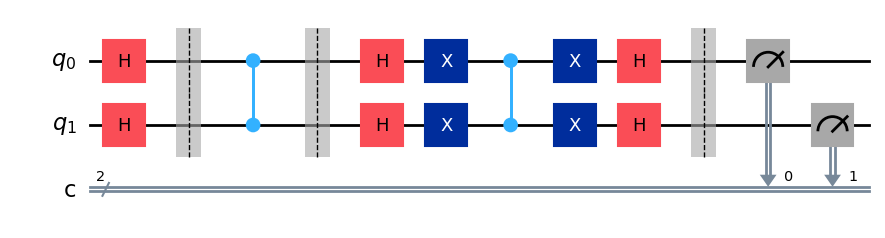

{'11': 1024}


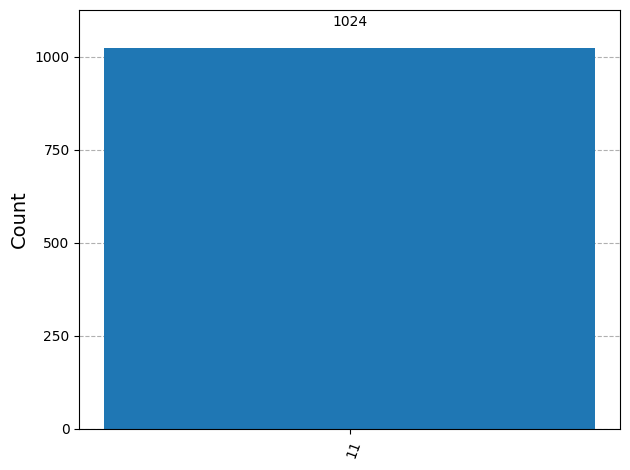

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

qc = QuantumCircuit(2, 2)

qc.h([0, 1])                    # equal start
qc.barrier()

qc.cz(0, 1)                     # oracle: marks node |11>
qc.barrier()

qc.h([0, 1])                    # spreading step (diffusion)
qc.x([0, 1])
qc.cz(0, 1)
qc.x([0, 1])
qc.h([0, 1])
qc.barrier()

qc.measure([0, 1], [0, 1])      # measure both qubits

display(qc.draw("mpl"))

sim = AerSimulator()
result = sim.run(transpile(qc, sim), shots=1024).result()
counts = result.get_counts()
print(counts)

plot_histogram(counts)

errors 0.0 0.0 -> {'11': 1024} | chance of 11: 1.0
errors 0.001 0.01 -> {'01': 12, '10': 9, '00': 8, '11': 995} | chance of 11: 0.972
errors 0.01 0.05 -> {'01': 57, '11': 889, '10': 41, '00': 37} | chance of 11: 0.868
errors 0.03 0.1 -> {'01': 114, '10': 105, '00': 87, '11': 718} | chance of 11: 0.701


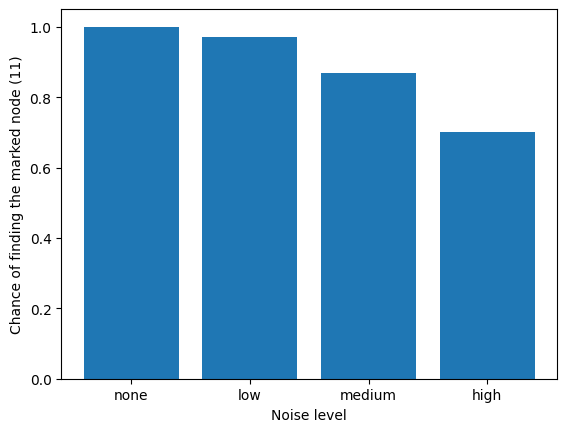

In [7]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

qc = QuantumCircuit(2, 2)
qc.h([0, 1])
qc.cz(0, 1)                                  # oracle
qc.h([0, 1]); qc.x([0, 1]); qc.cz(0, 1); qc.x([0, 1]); qc.h([0, 1])   # spreading
qc.measure([0, 1], [0, 1])

# error levels: (single-qubit gate error, two-qubit gate error)
levels = [(0.0, 0.0), (0.001, 0.01), (0.01, 0.05), (0.03, 0.10)]
success = []

for p1, p2 in levels:
    noise = NoiseModel()
    noise.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["h", "x"])
    noise.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cz"])
    sim = AerSimulator(noise_model=noise)
    counts = sim.run(transpile(qc, sim), shots=1024).result().get_counts()
    rate = counts.get("11", 0) / 1024
    success.append(rate)
    print("errors", p1, p2, "->", counts, "| chance of 11:", round(rate, 3))

import matplotlib.pyplot as plt
labels = ["none", "low", "medium", "high"]
plt.bar(labels, success)
plt.ylabel("Chance of finding the marked node (11)")
plt.xlabel("Noise level")
plt.ylim(0, 1.05)
plt.show()

Step 0 -> probability of marked node: 0.125
Step 1 -> probability of marked node: 0.781
Step 2 -> probability of marked node: 0.945
Step 3 -> probability of marked node: 0.33
Step 4 -> probability of marked node: 0.012
Step 5 -> probability of marked node: 0.548
Step 6 -> probability of marked node: 1.0
Step 7 -> probability of marked node: 0.577


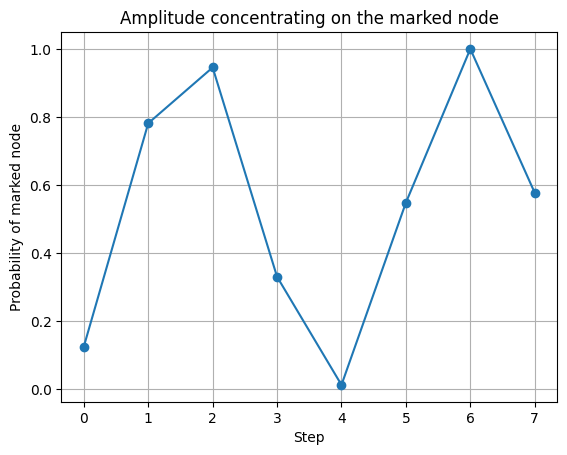

In [8]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

n = 3                     # 2 qubits = 4 nodes. Change to 3 for 8 nodes.
marked = 2**n - 1          # the marked node is |11...1>

def flip_marked(qc):
    # flips the sign of |11...1>
    if n == 2:
        qc.cz(0, 1)
    elif n == 3:
        qc.h(2); qc.ccx(0, 1, 2); qc.h(2)

def oracle(qc):
    flip_marked(qc)

def spread(qc):
    # diffusion: spreads amplitude towards the marked node
    qc.h(range(n)); qc.x(range(n))
    flip_marked(qc)
    qc.x(range(n)); qc.h(range(n))

qc = QuantumCircuit(n)
qc.h(range(n))             # equal start

probs = [Statevector.from_instruction(qc).probabilities()[marked]]

for step in range(1, 8):
    oracle(qc)
    spread(qc)
    probs.append(Statevector.from_instruction(qc).probabilities()[marked])

for s, p in enumerate(probs):
    print("Step", s, "-> probability of marked node:", round(p, 3))

plt.plot(range(len(probs)), probs, marker="o")
plt.xlabel("Step")
plt.ylabel("Probability of marked node")
plt.title("Amplitude concentrating on the marked node")
plt.grid(True)
plt.show()